# Problem 1 — Diabetes Prediction using NN   
   
*Dataset: Diabetes Dataset*   

*Data link : [data link](https://github.com/shekharkumar1412-cpu/Teaching\_Content/blob/main/MCA\_Rungta/DL/Practice\_Problems/diabetes.csv)*  

*Tasks to be done after loading the data*   

### Data Understanding & Preprocessing   

*  Display the shape, data types and summary statistics.   
*  Check for missing values.   
*  Identify whether any columns contain invalid zero values.   
*  Separate input features and target variables.   
*  Check the class distribution of the target.   
*  Split the data into training and testing sets.   
*  Identify whether numerical features have significantly different scales.   
*  Apply appropriate feature scaling. 


### Neural Network   
*  Build a binary classification neural network using Keras.   
*  Use at least one hidden layer.   
*  Use an appropriate activation function for the hidden layer.   
*  Use an appropriate activation function for the output layer.   
*  Use Binary Cross Entropy as the loss function.   
*  Train the model and plot training vs validation loss.   
*  Plot training vs validation accuracy.   

### Gradient Descent Experiment   
*  Train the same network using:   
*  SGD   
*  Mini-Batch Gradient Descent and Batch Gradient Descent.   
   
### Regularization   
*  Add Dropout to the network.   
*  Train models with:    
 -  Dropout = 0    
 - Dropout = 0.2   
 - Dropout = 0.5   
*  Compare training and validation performance.   
*  Determine whether the original model was overfitting.   
   
### Early Stopping   
*  Train the model for a sufficiently large number of epochs.   
*  Implement Early Stopping using validation loss.   
*  Experiment with different patience values.   
*  Identify the epoch at which the best model was obtained.   
*  Compare the model with and without Early Stopping.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.optimizers import SGD, Adam
from tensorflow.keras.callbacks import EarlyStopping

df = pd.read_csv('diabetes.csv')

print(df.shape)
print(df.dtypes)
print(df.describe())

print(df.isnull().sum())

cols_with_zeros = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
df[cols_with_zeros] = df[cols_with_zeros].replace(0, np.nan)
print(df.isnull().sum())

df.fillna(df.mean(), inplace=True)

X = df.drop('Outcome', axis=1)
y = df['Outcome']

print(y.value_counts())

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

def plot_metrics(history, title):
    plt.figure(figsize=(12, 4))
    
    plt.subplot(1, 2, 1)
    plt.plot(history.history['loss'], label='Train Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title(f'{title} - Loss')
    plt.legend()
    
    plt.subplot(1, 2, 2)
    plt.plot(history.history['accuracy'], label='Train Accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
    plt.title(f'{title} - Accuracy')
    plt.legend()
    
    plt.show()

base_model = Sequential()
base_model.add(Dense(32, input_dim=X_train.shape[1], activation='relu'))
base_model.add(Dense(16, activation='relu'))
base_model.add(Dense(1, activation='sigmoid'))
base_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

base_history = base_model.fit(X_train_scaled, y_train, validation_data=(X_test_scaled, y_test), epochs=100, batch_size=32, verbose=0)
plot_metrics(base_history, "Base Model")

sgd_model = Sequential()
sgd_model.add(Dense(32, input_dim=X_train.shape[1], activation='relu'))
sgd_model.add(Dense(16, activation='relu'))
sgd_model.add(Dense(1, activation='sigmoid'))
sgd_model.compile(optimizer=SGD(learning_rate=0.01), loss='binary_crossentropy', metrics=['accuracy'])

sgd_history = sgd_model.fit(X_train_scaled, y_train, validation_data=(X_test_scaled, y_test), epochs=100, batch_size=1, verbose=0)
plot_metrics(sgd_history, "Stochastic Gradient Descent (SGD)")

mbgd_model = Sequential()
mbgd_model.add(Dense(32, input_dim=X_train.shape[1], activation='relu'))
mbgd_model.add(Dense(16, activation='relu'))
mbgd_model.add(Dense(1, activation='sigmoid'))
mbgd_model.compile(optimizer=SGD(learning_rate=0.01), loss='binary_crossentropy', metrics=['accuracy'])

mbgd_history = mbgd_model.fit(X_train_scaled, y_train, validation_data=(X_test_scaled, y_test), epochs=100, batch_size=32, verbose=0)
plot_metrics(mbgd_history, "Mini-Batch Gradient Descent")

bgd_model = Sequential()
bgd_model.add(Dense(32, input_dim=X_train.shape[1], activation='relu'))
bgd_model.add(Dense(16, activation='relu'))
bgd_model.add(Dense(1, activation='sigmoid'))
bgd_model.compile(optimizer=SGD(learning_rate=0.01), loss='binary_crossentropy', metrics=['accuracy'])

bgd_history = bgd_model.fit(X_train_scaled, y_train, validation_data=(X_test_scaled, y_test), epochs=100, batch_size=len(X_train_scaled), verbose=0)
plot_metrics(bgd_history, "Batch Gradient Descent")

do_model = Sequential()
do_model.add(Dense(32, input_dim=X_train.shape[1], activation='relu'))
do_model.add(Dropout(0.0))
do_model.add(Dense(16, activation='relu'))
do_model.add(Dropout(0.2))
do_model.add(Dense(8, activation='relu'))
do_model.add(Dropout(0.5))
do_model.add(Dense(1, activation='sigmoid'))
do_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

do_history = do_model.fit(X_train_scaled, y_train, validation_data=(X_test_scaled, y_test), epochs=100, batch_size=32, verbose=0)
plot_metrics(do_history, "Custom Layered Dropout")

large_epoch_model = Sequential()
large_epoch_model.add(Dense(32, input_dim=X_train.shape[1], activation='relu'))
large_epoch_model.add(Dense(16, activation='relu'))
large_epoch_model.add(Dense(1, activation='sigmoid'))
large_epoch_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

large_history = large_epoch_model.fit(X_train_scaled, y_train, validation_data=(X_test_scaled, y_test), epochs=300, batch_size=32, verbose=0)
plot_metrics(large_history, "Model Without Early Stopping (300 Epochs)")

es_patience = EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)

es_model = Sequential()
es_model.add(Dense(32, input_dim=X_train.shape[1], activation='relu'))
es_model.add(Dense(16, activation='relu'))
es_model.add(Dense(1, activation='sigmoid'))
es_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

es_history = es_model.fit(X_train_scaled, y_train, validation_data=(X_test_scaled, y_test), epochs=300, batch_size=32, callbacks=[es_patience], verbose=0)
plot_metrics(es_history, "Model With Early Stopping (Patience 15)")

best_epoch = es_patience.best_epoch + 1
print(best_epoch)

plt.figure(figsize=(8, 5))
plt.plot(large_history.history['val_loss'], label='Without Early Stopping')
plt.plot(es_history.history['val_loss'], label='With Early Stopping')
plt.title('Validation Loss Comparison: Early Stopping vs Base Model')
plt.xlabel('Epochs')
plt.ylabel('Validation Loss')
plt.legend()
plt.show()

: 

# Problem 2 — Student Performance Prediction
*Dataset : Student Performance*
*Data link : [Link for data](https://github.com/shekharkumar1412-cpu/Teaching\_Content/blob/main/MCA\_Rungta/DL/Practice\_Problems/Student\_Performance.csv)*

*Tasks*

### A. Preprocessing
* Load the dataset.
* Check missing values.
* Identify numerical and categorical variables.
* Identify the target variable.
* Encode categorical variables.
* Apply feature scaling.

### B. Regression Neural Network
* Split the dataset into train, validation and test sets.
* Build a neural network for regression.
* Experiment with different numbers of hidden layers.
* Experiment with different numbers of neurons.
* Use an appropriate regression loss function.
* Plot training and validation loss.

### C. Gradient Descent
* Train the model using different optimizers.
* Compare SGD, Mini-Batch SGD and Batch.

### D. Overfitting
* Create a relatively large network.
* Train it without regularization.
* Identify evidence of overfitting.
* Add Dropout.
* Compare performance before and after Dropout.

### E. Early Stopping
* Train for a large number of epochs.
* Apply Early Stopping.
* Restore the best weights.
* Compare:
 - Without Early Stopping
 - Vs
 - With Early Stopping

Hours Studied                       0
Previous Scores                     0
Extracurricular Activities          0
Sleep Hours                         0
Sample Question Papers Practiced    0
Performance Index                   0
dtype: int64
Hours Studied                         int64
Previous Scores                       int64
Extracurricular Activities              str
Sleep Hours                           int64
Sample Question Papers Practiced      int64
Performance Index                   float64
dtype: object
Categorical Variables: ['Extracurricular Activities']
Numerical Variables: ['Hours Studied', 'Previous Scores', 'Sleep Hours', 'Sample Question Papers Practiced', 'Performance Index']


C:\Users\atulv\AppData\Local\Temp\ipykernel_4312\345707787.py:17: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include=['object']).columns
d:\SysFolders\Mini_Conda\envs\dlp_project\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


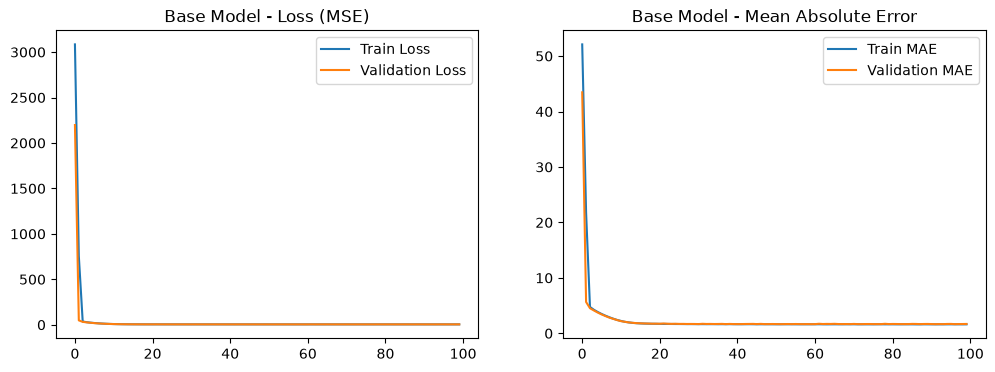

d:\SysFolders\Mini_Conda\envs\dlp_project\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


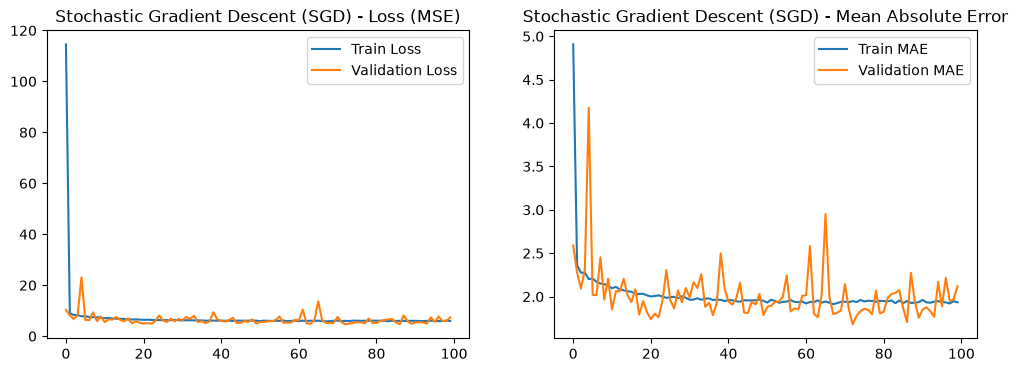

d:\SysFolders\Mini_Conda\envs\dlp_project\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


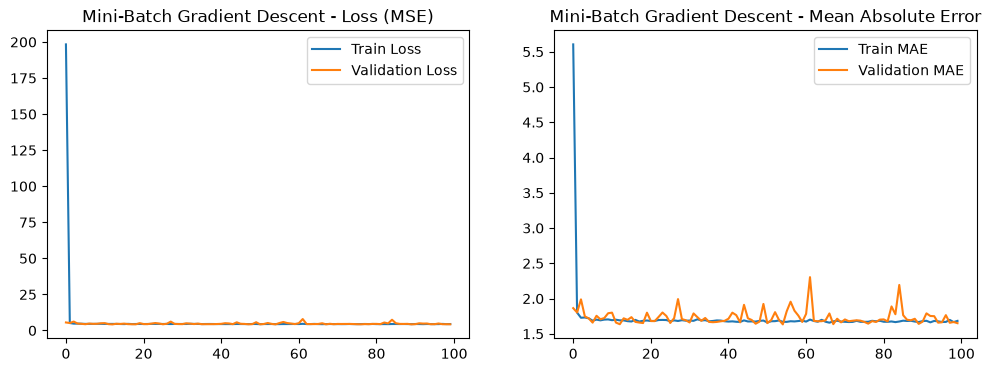

d:\SysFolders\Mini_Conda\envs\dlp_project\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


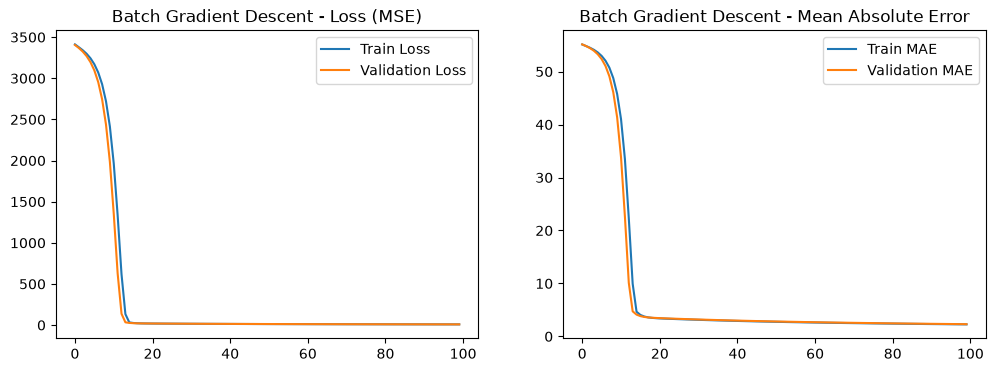

d:\SysFolders\Mini_Conda\envs\dlp_project\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


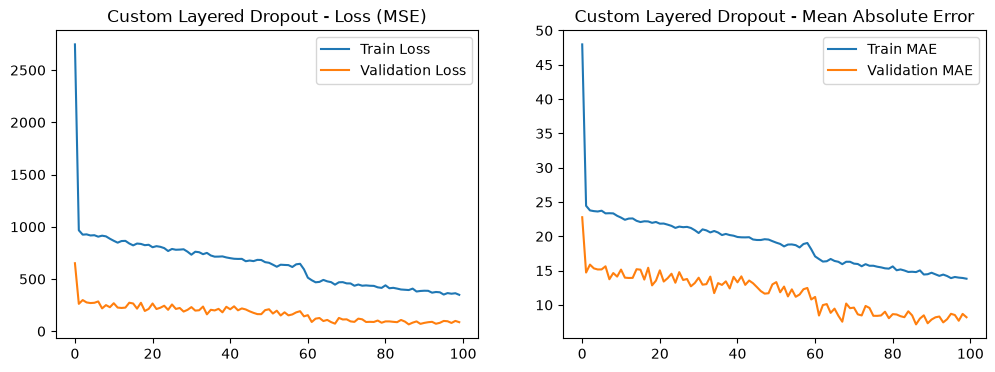

d:\SysFolders\Mini_Conda\envs\dlp_project\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


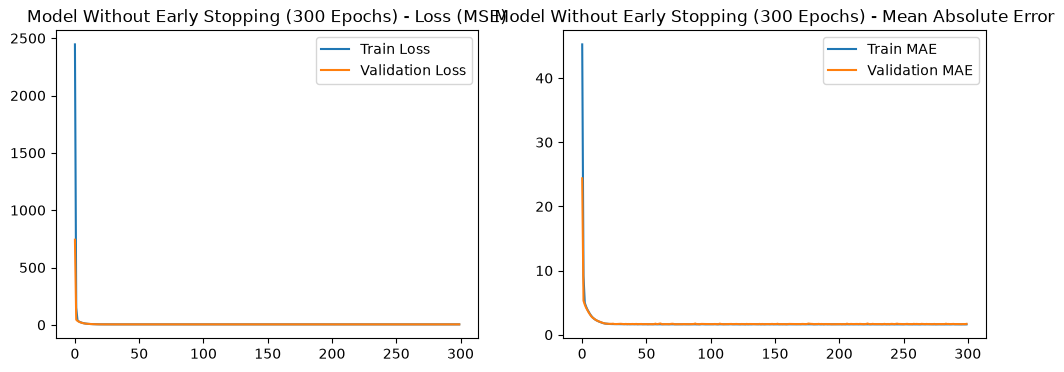

d:\SysFolders\Mini_Conda\envs\dlp_project\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


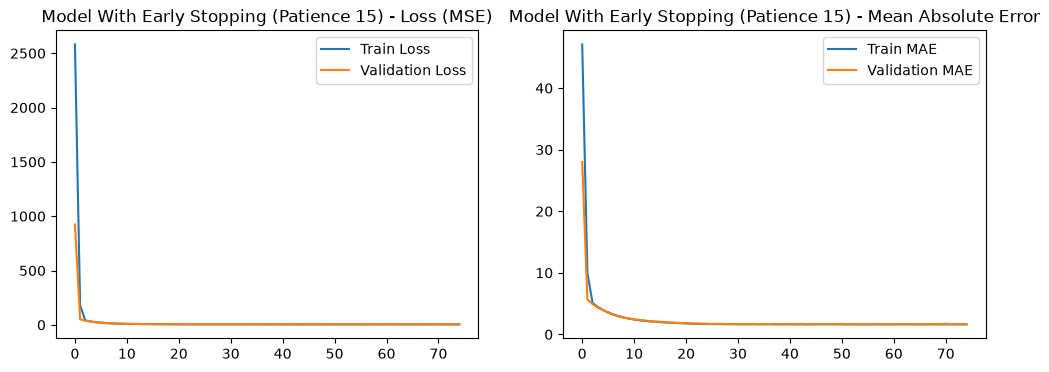

60


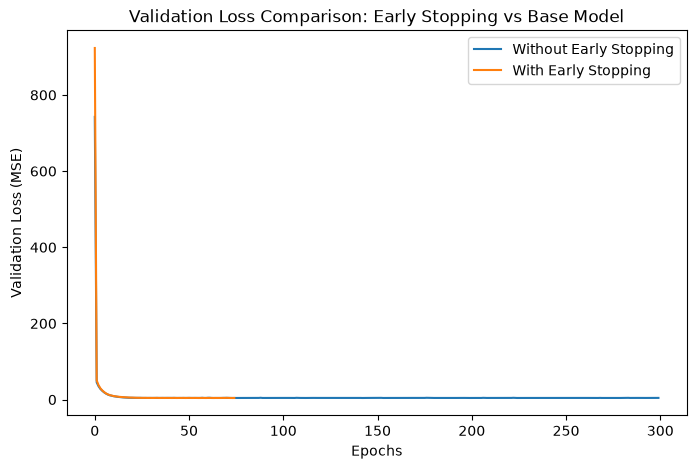

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.optimizers import SGD, Adam
from tensorflow.keras.callbacks import EarlyStopping

df = pd.read_csv('Student_Performance.csv')

print(df.isnull().sum())
print(df.dtypes)

categorical_cols = df.select_dtypes(include=['object']).columns
numerical_cols = df.select_dtypes(exclude=['object']).columns
print("Categorical Variables:", list(categorical_cols))
print("Numerical Variables:", list(numerical_cols))

df['Extracurricular Activities'] = df['Extracurricular Activities'].map({'Yes': 1, 'No': 0})

X = df.drop('Performance Index', axis=1)
y = df['Performance Index']

X_train_full, X_test, y_train_full, y_test = train_test_split(X, y, test_size=0.15, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train_full, y_train_full, test_size=0.1765, random_state=42) 

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

def plot_metrics(history, title):
    plt.figure(figsize=(12, 4))
    
    plt.subplot(1, 2, 1)
    plt.plot(history.history['loss'], label='Train Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title(f'{title} - Loss (MSE)')
    plt.legend()
    
    plt.subplot(1, 2, 2)
    plt.plot(history.history['mae'], label='Train MAE')
    plt.plot(history.history['val_mae'], label='Validation MAE')
    plt.title(f'{title} - Mean Absolute Error')
    plt.legend()
    
    plt.show()

base_model = Sequential()
base_model.add(Dense(32, input_dim=X_train.shape[1], activation='relu'))
base_model.add(Dense(16, activation='relu'))
base_model.add(Dense(1))
base_model.compile(optimizer='adam', loss='mse', metrics=['mae'])

base_history = base_model.fit(X_train_scaled, y_train, validation_data=(X_val_scaled, y_val), epochs=100, batch_size=32, verbose=0)
plot_metrics(base_history, "Base Model")

sgd_model = Sequential()
sgd_model.add(Dense(32, input_dim=X_train.shape[1], activation='relu'))
sgd_model.add(Dense(16, activation='relu'))
sgd_model.add(Dense(1))
sgd_model.compile(optimizer=SGD(learning_rate=0.001), loss='mse', metrics=['mae'])

sgd_history = sgd_model.fit(X_train_scaled, y_train, validation_data=(X_val_scaled, y_val), epochs=100, batch_size=1, verbose=0)
plot_metrics(sgd_history, "Stochastic Gradient Descent (SGD)")

mbgd_model = Sequential()
mbgd_model.add(Dense(32, input_dim=X_train.shape[1], activation='relu'))
mbgd_model.add(Dense(16, activation='relu'))
mbgd_model.add(Dense(1))
mbgd_model.compile(optimizer=SGD(learning_rate=0.001), loss='mse', metrics=['mae'])

mbgd_history = mbgd_model.fit(X_train_scaled, y_train, validation_data=(X_val_scaled, y_val), epochs=100, batch_size=32, verbose=0)
plot_metrics(mbgd_history, "Mini-Batch Gradient Descent")

bgd_model = Sequential()
bgd_model.add(Dense(32, input_dim=X_train.shape[1], activation='relu'))
bgd_model.add(Dense(16, activation='relu'))
bgd_model.add(Dense(1))
bgd_model.compile(optimizer=SGD(learning_rate=0.001), loss='mse', metrics=['mae'])

bgd_history = bgd_model.fit(X_train_scaled, y_train, validation_data=(X_val_scaled, y_val), epochs=100, batch_size=len(X_train_scaled), verbose=0)
plot_metrics(bgd_history, "Batch Gradient Descent")

do_model = Sequential()
do_model.add(Dense(32, input_dim=X_train.shape[1], activation='relu'))
do_model.add(Dropout(0.0))
do_model.add(Dense(16, activation='relu'))
do_model.add(Dropout(0.2))
do_model.add(Dense(8, activation='relu'))
do_model.add(Dropout(0.5))
do_model.add(Dense(1))
do_model.compile(optimizer='adam', loss='mse', metrics=['mae'])

do_history = do_model.fit(X_train_scaled, y_train, validation_data=(X_val_scaled, y_val), epochs=100, batch_size=32, verbose=0)
plot_metrics(do_history, "Custom Layered Dropout")

large_epoch_model = Sequential()
large_epoch_model.add(Dense(32, input_dim=X_train.shape[1], activation='relu'))
large_epoch_model.add(Dense(16, activation='relu'))
large_epoch_model.add(Dense(1))
large_epoch_model.compile(optimizer='adam', loss='mse', metrics=['mae'])

large_history = large_epoch_model.fit(X_train_scaled, y_train, validation_data=(X_val_scaled, y_val), epochs=300, batch_size=32, verbose=0)
plot_metrics(large_history, "Model Without Early Stopping (300 Epochs)")

es_patience = EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)

es_model = Sequential()
es_model.add(Dense(32, input_dim=X_train.shape[1], activation='relu'))
es_model.add(Dense(16, activation='relu'))
es_model.add(Dense(1))
es_model.compile(optimizer='adam', loss='mse', metrics=['mae'])

es_history = es_model.fit(X_train_scaled, y_train, validation_data=(X_val_scaled, y_val), epochs=300, batch_size=32, callbacks=[es_patience], verbose=0)
plot_metrics(es_history, "Model With Early Stopping (Patience 15)")

best_epoch = es_patience.best_epoch + 1
print(best_epoch)

plt.figure(figsize=(8, 5))
plt.plot(large_history.history['val_loss'], label='Without Early Stopping')
plt.plot(es_history.history['val_loss'], label='With Early Stopping')
plt.title('Validation Loss Comparison: Early Stopping vs Base Model')
plt.xlabel('Epochs')
plt.ylabel('Validation Loss (MSE)')
plt.legend()
plt.show()